# GRU para formación de colas (CAETEC)

Entrena y evalúa `GRUModel` con `TimeSeriesSplit` de 5 folds, muestra métricas por fold y las compara contra líneas base.

`GRUModel` hereda de `TCNModel` la preparación de ventanas por robot (ventana en *t−1*, etiqueta en *t*), el escalado ajustado solo con train y la evaluación; solo cambia la arquitectura. Así los resultados son comparables con el TCN.

## 1. Configuración

In [21]:
# ====== RUTAS (ajusta a tu Drive) ======
DATA_PATH = "/content/drive/MyDrive/Datos/Procesado/dataset_final_serie_tiempo.parquet"
MODELING_PARENT = "/content/modeling"

# ====== EXPERIMENTO-00 ======
TASK = "regression" # "regression" (pct_posible_cola) | "classification" (hay_cola)
WINDOW = 48 # 12 (6 h) | 24 (12 h) | 48 (24 h)
VERSION = "base" # "base" | "norm" | "bi"
LEARNING_RATE = 1e-3
EPOCHS = 50
BATCH = 128
N_SPLITS = 5
QUICK = False # False = Entrenamiento completo | True = prueba rápida (1 fold, 3 épocas)
TUNE_THRESHOLD = True # Busca el umbral con mejor F1 en la validación de cada fold (nunca en test)
SEED = 42
TARGET = "pct_posible_cola"

## 2. Imports y datos

In [22]:
import sys, os
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
# ---- Encontrar el paquete `modeling` (gru_model.py, tcn_model.py, model_base.py) ----
# 1) Si ya están en MODELING_PARENT/modeling/ se usan esos.
# 2) Si no, se clona el repo (rama REPO_BRANCH) y se usa vms/notebooks/modeling/.
# 3) Si gru_model.py aún no está en GitHub, se piden los 3 .py para subirlos a mano.
REPO_URL = "https://github.com/kamimartinez/VMS-prediction.git"
REPO_BRANCH = "main"
NEEDED = ["gru_model.py", "tcn_model.py", "model_base.py"]

def _has_files(folder):
    return all(os.path.exists(os.path.join(folder, "modeling", f)) for f in NEEDED)

if not _has_files(MODELING_PARENT) and IN_COLAB:
    os.system(f"rm -rf /content/vms && git clone -q -b {REPO_BRANCH} {REPO_URL} /content/vms")
    if _has_files("/content/vms/notebooks"):
        MODELING_PARENT = "/content/vms/notebooks"
    else:
        print("gru_model.py no está en GitHub todavía. Sube gru_model.py, tcn_model.py y model_base.py:")
        from google.colab import files
        os.makedirs(os.path.join(MODELING_PARENT, "modeling"), exist_ok=True)
        for name, data in files.upload().items():
            with open(os.path.join(MODELING_PARENT, "modeling", name), "wb") as fh:
                fh.write(data)

if not _has_files(MODELING_PARENT):
    raise FileNotFoundError(f"Faltan {NEEDED} en {MODELING_PARENT}/modeling/")
if MODELING_PARENT not in sys.path:
    sys.path.insert(0, MODELING_PARENT)
print("Usando módulos de:", os.path.join(MODELING_PARENT, "modeling"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, mean_absolute_error, mean_squared_error, r2_score)
from tensorflow.keras.callbacks import EarlyStopping

from modeling.gru_model import GRUModel

np.random.seed(SEED); tf.random.set_seed(SEED)
print("TensorFlow", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Usando módulos de: /content/vms/notebooks/modeling
TensorFlow 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [23]:
df = pd.read_parquet(DATA_PATH)
# prepare() espera temporada como texto tipo object (con pandas 3 llega como 'str')
df["temporada"] = df["temporada"].astype(object)
print(df.shape)
print(df.dtypes.to_string())
df.head()

(179850, 24)
ms                                    object
bloque_tiempo                 datetime64[ns]
total_ordenios                         int64
produccion_promedio                  float64
duracion_total_min                   float64
patadas_totales                        int64
desviaciones_leche_totales           float64
ordenios_con_lavado                    int64
pct_primer_parto                     float64
pct_fresca                           float64
pct_alta                             float64
pct_baja                             float64
pct_extendida                        float64
hubo_ordenios                          int64
pct_ocupacion_robot                  float64
hubo_lavado                            int64
ordenios_otros_robots                  int64
hora                                   int32
dia_semana                             int32
temporada                             object
min_desde_alimento                   float64
vacas_activas_dia                      int

,ms,bloque_tiempo,total_ordenios,produccion_promedio,duracion_total_min,patadas_totales,desviaciones_leche_totales,ordenios_con_lavado,pct_primer_parto,pct_fresca,...,pct_ocupacion_robot,hubo_lavado,ordenios_otros_robots,hora,dia_semana,temporada,min_desde_alimento,vacas_activas_dia,sin_etapa,pct_posible_cola
0,VMS 3,2022-08-01 00:00:00,2,13.375,19.066667,0,0.0,0,0.0,0.0,...,0.635556,0,0,0,0,verano,570.0,31,1,1.000000
1,VMS 3,2022-08-01 00:30:00,1,21.470,6.366667,0,0.0,0,0.0,0.0,...,0.212222,0,0,0,0,verano,600.0,31,1,0.000000
2,VMS 1,2022-08-01 01:00:00,3,11.030,16.783333,0,0.0,0,0.0,0.0,...,0.559444,0,1,1,0,verano,630.0,31,1,0.666667
3,VMS 3,2022-08-01 01:00:00,1,16.690,6.650000,0,0.0,0,0.0,0.0,...,0.221667,0,3,1,0,verano,630.0,31,1,0.000000
4,VMS 1,2022-08-01 01:30:00,0,NaN,0.000000,0,0.0,0,0.0,0.0,...,0.000000,0,0,1,0,verano,660.0,31,1,0.000000


## 3. Ventanas 3D por robot

La ventana termina en el bloque *t−1* y la etiqueta es la del bloque *t*, así no se usan las variables mecánicas del bloque que se quiere predecir.

In [24]:
gru = GRUModel(task=TASK, window=WINDOW, learning_rate=LEARNING_RATE)
X_seq, y_seq, meta = gru.prepare(df, df[TARGET])
print("X_seq:", X_seq.shape, "(N, ventana, features)")
print("y_seq:", y_seq.shape)
print("Features:", gru.feature_names_)
print("Periodo objetivo:", meta["bloque_tiempo"].min(), "->", meta["bloque_tiempo"].max())
print("Ventanas por robot:\n", meta["ms"].value_counts().to_string())
if TASK == "classification":
    print(f"Proporción hay_cola=1: {y_seq.mean():.3f}")
else:
    print(f"pct_posible_cola promedio: {y_seq.mean():.3f}")

X_seq: (179706, 48, 27) (N, ventana, features)
y_seq: (179706,)
Features: ['total_ordenios', 'produccion_promedio', 'duracion_total_min', 'patadas_totales', 'desviaciones_leche_totales', 'ordenios_con_lavado', 'pct_primer_parto', 'pct_fresca', 'pct_alta', 'pct_baja', 'pct_extendida', 'hubo_ordenios', 'pct_ocupacion_robot', 'hubo_lavado', 'ordenios_otros_robots', 'hora', 'dia_semana', 'min_desde_alimento', 'vacas_activas_dia', 'sin_etapa', 'pct_posible_cola', 'temp_invierno', 'temp_primavera', 'temp_verano', 'temp_otoño', 'hora_sin', 'hora_cos']
Periodo objetivo: 2022-08-02 00:00:00 -> 2025-12-31 23:30:00
Ventanas por robot:
 ms
VMS 3    59904
VMS 1    59902
VMS 2    59900
pct_posible_cola promedio: 0.302


## 4. Líneas base

- **Mayoritaria / media**: predice siempre lo más frecuente del train.
- **Persistencia**: repite el valor del bloque anterior del mismo robot (dato disponible al predecir).

In [25]:
# Valor del bloque anterior (t-1) del mismo robot, alineado con cada ventana
lookup = df[["ms", "bloque_tiempo", TARGET]].copy()
lookup["bloque_tiempo"] = pd.to_datetime(lookup["bloque_tiempo"]) + pd.Timedelta(minutes=30)
lookup = lookup.rename(columns={TARGET: "prev"})
prev = meta[["ms", "bloque_tiempo"]].merge(lookup, on=["ms", "bloque_tiempo"], how="left")["prev"].to_numpy()
persist = np.nan_to_num(prev, nan=np.nanmean(prev))
persist_bin = (persist > gru.threshold).astype(float)
print("Persistencia disponible en", (~np.isnan(prev)).mean().round(3), "de las ventanas")

Persistencia disponible en 1.0 de las ventanas


## 5. Funciones de métricas

In [26]:
def cls_metrics(y_true, y_prob, thr=0.5):
    y_true = np.asarray(y_true).astype(int); y_pred = (np.asarray(y_prob) >= thr).astype(int)
    try: auc = roc_auc_score(y_true, y_prob)
    except ValueError: auc = np.nan
    return {"Accuracy": accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred, zero_division=0),
            "Recall": recall_score(y_true, y_pred, zero_division=0),
            "F1": f1_score(y_true, y_pred, zero_division=0),
            "AUC": auc}

def reg_metrics(y_true, y_pred, thr=0.5):
    # Además de MAE/RMSE/R2 se reportan precisión, recall y F1 de hay_cola (> 0.5) para comparar con el criterio de éxito (F1 > 0.60)
    y_true = np.asarray(y_true, dtype=float); y_pred = np.asarray(y_pred, dtype=float)
    cola_true = (y_true > gru.threshold).astype(int); cola_pred = (y_pred >= thr).astype(int)
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
            "R2": r2_score(y_true, y_pred),
            "Precision_cola": precision_score(cola_true, cola_pred, zero_division=0),
            "Recall_cola": recall_score(cola_true, cola_pred, zero_division=0),
            "F1_cola": f1_score(cola_true, cola_pred, zero_division=0)}

def metrics(y_true, y_hat, thr=0.5):
    return cls_metrics(y_true, y_hat, thr) if TASK == "classification" else reg_metrics(y_true, y_hat, thr)

## 6. Entrenamiento con TimeSeriesSplit

In [27]:
epochs = 3 if QUICK else EPOCHS
tscv = TimeSeriesSplit(n_splits=N_SPLITS)
folds = list(tscv.split(X_seq))
if QUICK:
    folds = folds[:1]
    print("MODO RÁPIDO: 1 fold, 3 épocas")

rows_model, rows_active, rows_base, rows_persist = [], [], [], []
histories, thresholds, last = [], [], {}

for k, (tr, te) in enumerate(folds, start=1):
    print(f"\n===== Fold {k}/{len(folds)} | train={len(tr):,} test={len(te):,} =====")
    print("Test:", meta["bloque_tiempo"].iloc[te].min(), "->", meta["bloque_tiempo"].iloc[te].max())
    tf.keras.backend.clear_session()

    # Validación cronológica: el último 10 % del train (no aleatorio)
    n_val = max(1, int(len(tr) * 0.1))
    tr_fit, va = tr[:-n_val], tr[-n_val:]

    X_tr, X_va, X_te = gru.scale(X_seq[tr_fit], X_seq[va], X_seq[te])   # scaler ajustado solo con train
    y_tr, y_va, y_te = y_seq[tr_fit], y_seq[va], y_seq[te]

    model = gru.compile(input_shape=X_tr.shape[1:], v=VERSION)
    if k == 1:
        model.summary()

    hist = model.fit(X_tr, y_tr, epochs=epochs, batch_size=BATCH, validation_data=(X_va, y_va),
                     class_weight=gru.class_weights(y_tr),          # None en regresión
                     callbacks=[EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)],
                     verbose=2)
    histories.append(hist.history)

    thr = gru.best_threshold(model, X_va, y_va)[0] if TUNE_THRESHOLD else 0.5
    thresholds.append(thr)
    print(f"Umbral usado en el fold {k}: {thr:.2f}")

    y_hat = model.predict(X_te, batch_size=512, verbose=0).ravel()
    rows_model.append({"fold": k, "umbral": thr, **metrics(y_te, y_hat, thr)})

    # Solo bloques con ordeños (análisis retrospectivo)
    if "hubo_ordenios" in meta.columns:
        act = meta["hubo_ordenios"].to_numpy()[te] == 1
        rows_active.append({"fold": k, **metrics(y_te[act], y_hat[act], thr)})

    # Líneas base
    if TASK == "classification":
        majority = float(y_tr.mean() > 0.5)
        rows_base.append({"fold": k, **cls_metrics(y_te, np.full(len(y_te), majority))})
        rows_persist.append({"fold": k, **cls_metrics(y_te, persist_bin[te])})
    else:
        rows_base.append({"fold": k, **reg_metrics(y_te, np.full(len(y_te), y_tr.mean()))})
        rows_persist.append({"fold": k, **reg_metrics(y_te, persist[te])})

    last = dict(model=model, history=hist, X_te=X_te, y_te=y_te, y_hat=y_hat, te=te, thr=thr)


===== Fold 1/5 | train=29,951 test=29,951 =====
Test: 2023-02-26 00:30:00 -> 2023-09-22 00:30:00


Model: "gru_base"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 48, 64)         │        17,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 48, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, 32)             │         9,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 28,353 (110.75 KB)

 Trainable params: 28,353 (110.75 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
211/211 - 4s - 20ms/step - loss: 0.0557 - mae: 0.1492 - rmse: 0.2361 - val_loss: 0.0561 - val_mae: 0.1468 - val_rmse: 0.2368
Epoch 2/50
211/211 - 2s - 10ms/step - loss: 0.0462 - mae: 0.1236 - rmse: 0.2148 - val_loss: 0.0551 - val_mae: 0.1589 - val_rmse: 0.2347
Epoch 3/50
211/211 - 3s - 14ms/step - loss: 0.0452 - mae: 0.1224 - rmse: 0.2127 - val_loss: 0.0552 - val_mae: 0.1682 - val_rmse: 0.2350
Epoch 4/50
211/211 - 4s - 20ms/step - loss: 0.0449 - mae: 0.1225 - rmse: 0.2118 - val_loss: 0.0544 - val_mae: 0.1594 - val_rmse: 0.2333
Epoch 5/50
211/211 - 2s - 10ms/step - loss: 0.0446 - mae: 0.1220 - rmse: 0.2112 - val_loss: 0.0543 - val_mae: 0.1590 - val_rmse: 0.2331
Epoch 6/50
211/211 - 2s - 10ms/step - loss: 0.0442 - mae: 0.1215 - rmse: 0.2103 - val_loss: 0.0543 - val_mae: 0.1615 - val_rmse: 0.2330
Epoch 7/50
211/211 - 2s - 10ms/step - loss: 0.0439 - mae: 0.1215 - rmse: 0.2096 - val_loss: 0.0546 - val_mae: 0.1659 - val_rmse: 0.2338
Epoch 8/50
211/211 - 3s - 15ms/step - loss: 0.04

## 7. Resultados por fold

In [28]:
def summarize(rows, name):
    d = pd.DataFrame(rows).set_index("fold")
    d.loc["media"] = d.mean(); d.loc["std"] = d.iloc[:-1].std()
    print(f"\n--- {name} ---"); display(d.round(4)); return d

res_model   = summarize(rows_model,   f"GRU ({VERSION}, ventana={WINDOW}) - todos los bloques")
if rows_active:
    res_active = summarize(rows_active, "GRU - solo bloques con ordeños")
res_base    = summarize(rows_base,    "Base: " + ("clase mayoritaria" if TASK == "classification" else "media del train"))
res_persist = summarize(rows_persist, "Base: persistencia (bloque anterior)")


--- GRU (base, ventana=48) - todos los bloques ---


,umbral,MAE,RMSE,R2,Precision_cola,Recall_cola,F1_cola
fold,,,,,,,
1,0.1400,0.2233,0.2820,-0.0142,0.0918,0.6741,0.1616
2,0.1500,0.2649,0.3499,-0.0282,0.2266,0.5445,0.3200
3,0.2500,0.3139,0.3699,-0.0017,0.3125,0.6243,0.4165
4,0.2900,0.3131,0.3681,0.0992,0.4231,0.9738,0.5899
5,0.4000,0.3295,0.3799,0.0425,0.6314,0.8960,0.7408
media,0.2460,0.2889,0.3500,0.0195,0.3371,0.7425,0.4458
std,0.1074,0.0440,0.0395,0.0518,0.2043,0.1837,0.2265



--- GRU - solo bloques con ordeños ---


,MAE,RMSE,R2,Precision_cola,Recall_cola,F1_cola
fold,,,,,,
1,0.2652,0.3340,-0.0333,0.1388,0.6741,0.2302
2,0.3140,0.3985,-0.1837,0.2750,0.5445,0.3654
3,0.3330,0.3919,-0.1169,0.3606,0.6243,0.4571
4,0.3041,0.3647,0.0183,0.4750,0.9738,0.6386
5,0.3287,0.3813,-0.2100,0.6676,0.8960,0.7651
media,0.3090,0.3741,-0.1051,0.3834,0.7425,0.4913
std,0.0271,0.0258,0.0971,0.2008,0.1837,0.2132



--- Base: media del train ---


,MAE,RMSE,R2,Precision_cola,Recall_cola,F1_cola
fold,,,,,,
1,0.1767,0.2864,-0.0457,0.0,0.0,0.0
2,0.2653,0.3713,-0.1579,0.0,0.0,0.0
3,0.3304,0.4189,-0.2851,0.0,0.0,0.0
4,0.4055,0.4777,-0.5172,0.0,0.0,0.0
5,0.4732,0.5331,-0.8849,0.0,0.0,0.0
media,0.3302,0.4175,-0.3782,0.0,0.0,0.0
std,0.1161,0.0953,0.3331,0.0,0.0,0.0



--- Base: persistencia (bloque anterior) ---


,MAE,RMSE,R2,Precision_cola,Recall_cola,F1_cola
fold,,,,,,
1,0.2092,0.3823,-0.8634,0.0978,0.2244,0.1362
2,0.2964,0.4508,-0.7069,0.2173,0.4339,0.2896
3,0.3526,0.4866,-0.7335,0.2975,0.5177,0.3779
4,0.3733,0.4954,-0.6314,0.4555,0.6698,0.5422
5,0.3413,0.4648,-0.4328,0.6375,0.7954,0.7078
media,0.3146,0.4560,-0.6736,0.3411,0.5282,0.4107
std,0.0653,0.0448,0.1585,0.2106,0.2195,0.2217


## 8. Comparación contra líneas base

El porcentaje de bloques con cola cambia mucho entre folds (sube con el tiempo), así que la exactitud sola engaña. Mira F1 (criterio de éxito: **F1 > 0.60**; en regresión se usa `F1_cola`) y que la GRU supere a la persistencia.

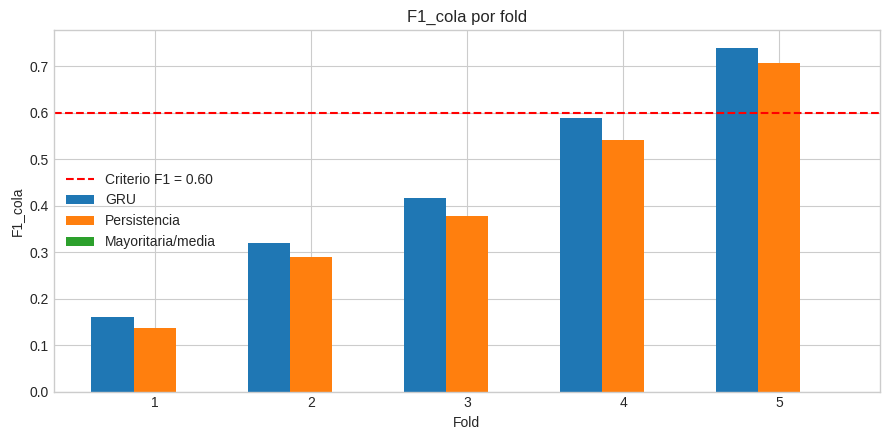

F1_cola medio  GRU: 0.4458 | persistencia: 0.4107 | base: 0.0000
MAE medio  GRU: 0.2889 | persistencia: 0.3146 | base: 0.3302


In [29]:
key = "F1" if TASK == "classification" else "F1_cola"
n = len(folds); x = np.arange(1, n + 1); w = 0.27

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(x - w, res_model[key].iloc[:n],   w, label="GRU")
ax.bar(x,     res_persist[key].iloc[:n], w, label="Persistencia")
ax.bar(x + w, res_base[key].iloc[:n],    w, label="Mayoritaria/media")
ax.axhline(0.60, color="red", ls="--", label="Criterio F1 = 0.60")
ax.set_xticks(x); ax.set_xlabel("Fold"); ax.set_ylabel(key)
ax.set_title(f"{key} por fold"); ax.legend(); plt.tight_layout(); plt.show()

print(f"{key} medio  GRU: {res_model.loc['media', key]:.4f} | "
      f"persistencia: {res_persist.loc['media', key]:.4f} | "
      f"base: {res_base.loc['media', key]:.4f}")
if TASK == "regression":
    print(f"MAE medio  GRU: {res_model.loc['media', 'MAE']:.4f} | "
          f"persistencia: {res_persist.loc['media', 'MAE']:.4f} | "
          f"base: {res_base.loc['media', 'MAE']:.4f}")

## 9. Curvas de entrenamiento (todos los folds)

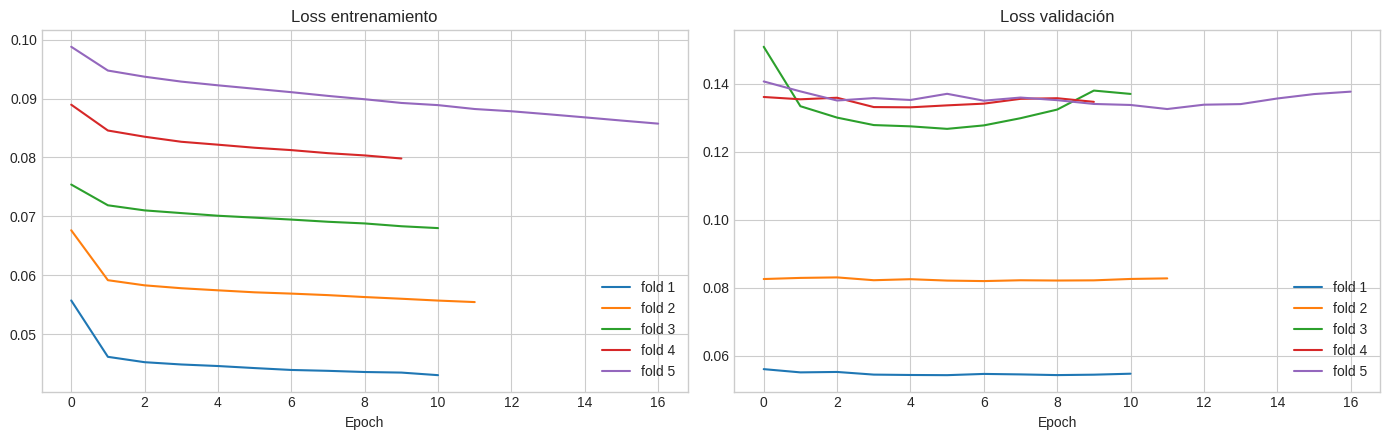

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for k, h in enumerate(histories, start=1):
    axes[0].plot(h["loss"], label=f"fold {k}")
    axes[1].plot(h["val_loss"], label=f"fold {k}")
axes[0].set_title("Loss entrenamiento"); axes[1].set_title("Loss validación")
for a in axes: a.set_xlabel("Epoch"); a.legend()
plt.tight_layout(); plt.show()

## 10. Detalle del último fold (curvas, matriz de confusión / ROC o residuales)


=== TEST SET REGRESSION METRICS ===
Metric    Value
   MAE 0.329474
  RMSE 0.379934
    R2 0.042507


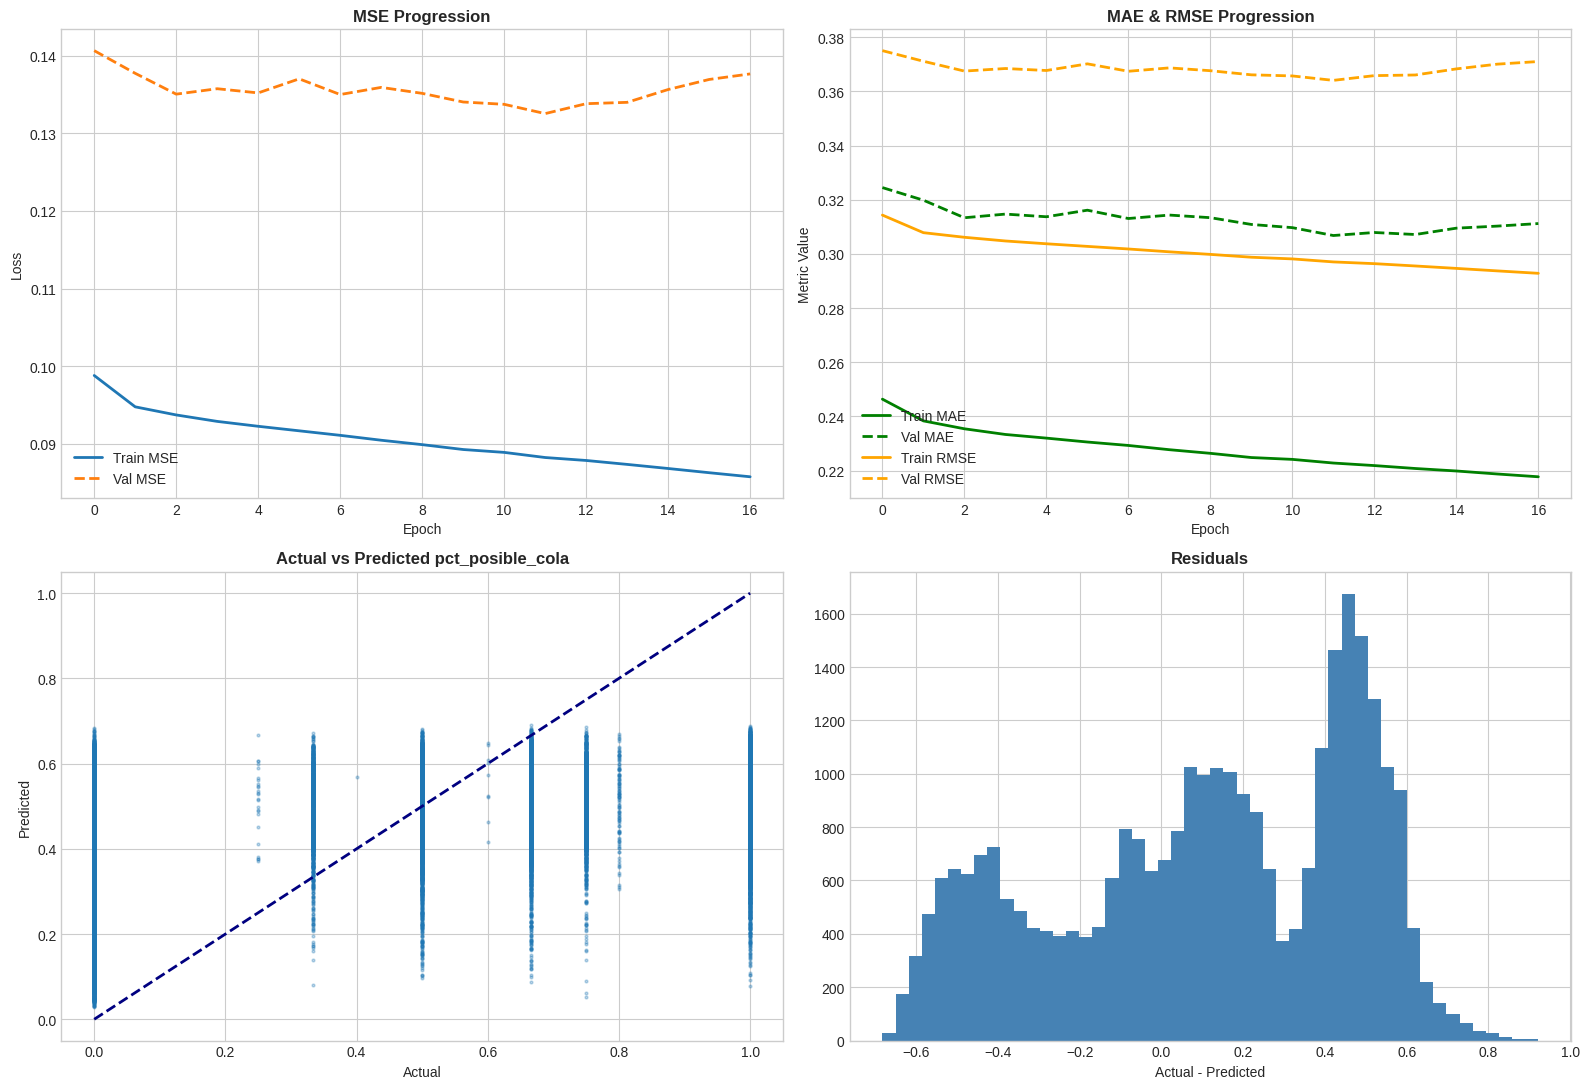

In [31]:
df_pred, df_metrics = gru.evaluate(last["model"], last["history"], last["X_te"], last["y_te"], threshold=last["thr"])

## 11. Predicción vs. real en una semana (un robot)

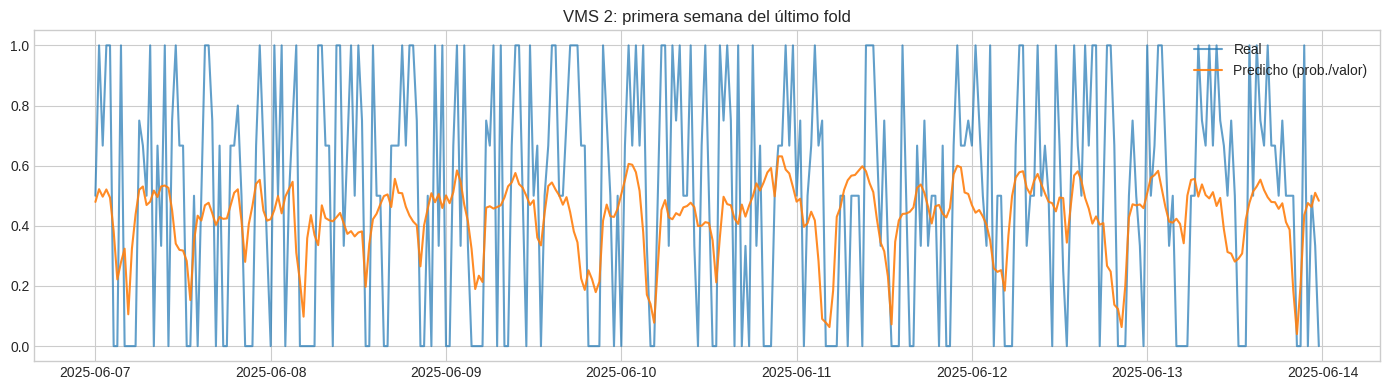

In [32]:
m = meta.iloc[last["te"]].copy()
m["real"] = last["y_te"]; m["pred"] = last["y_hat"]
robot = m["ms"].iloc[0]
s = m[m["ms"] == robot].head(336)          # 336 bloques = 7 días

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(s["bloque_tiempo"], s["real"], label="Real", alpha=0.7)
ax.plot(s["bloque_tiempo"], s["pred"], label="Predicho (prob./valor)", alpha=0.9)
ax.set_title(f"{robot}: primera semana del último fold"); ax.legend()
plt.tight_layout(); plt.show()

## 12. Importancia de variables (por permutación, último fold)

Desordena una variable a la vez y mide cuánto empeora la métrica. Más caída = más importante. Se muestrea para que corra rápido.

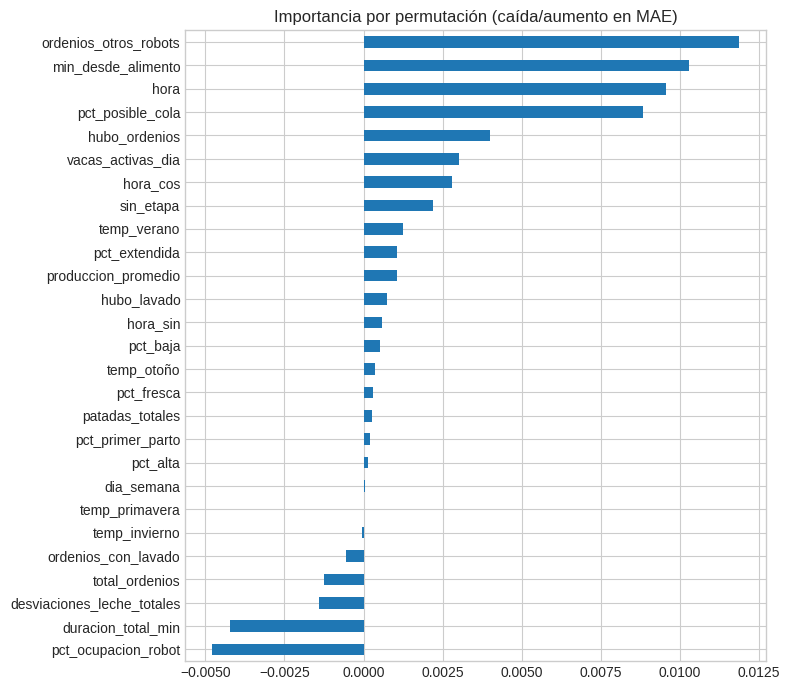

In [33]:
rng = np.random.default_rng(SEED)
Xp, yp = last["X_te"], last["y_te"]
idx = rng.choice(len(Xp), size=min(5000, len(Xp)), replace=False)
Xs, ys = Xp[idx], yp[idx]
mkey = "F1" if TASK == "classification" else "MAE"

base_val = metrics(ys, last["model"].predict(Xs, batch_size=512, verbose=0).ravel(), last["thr"])[mkey]
imp = {}
for j, name in enumerate(gru.feature_names_):
    Xperm = Xs.copy()
    Xperm[:, :, j] = Xperm[rng.permutation(len(Xs)), :, j]    # permuta la variable entre muestras
    v = metrics(ys, last["model"].predict(Xperm, batch_size=512, verbose=0).ravel(), last["thr"])[mkey]
    imp[name] = (base_val - v) if TASK == "classification" else (v - base_val)

imp = pd.Series(imp).sort_values()
imp.plot.barh(figsize=(8, 7)); plt.title(f"Importancia por permutación (caída/aumento en {mkey})")
plt.tight_layout(); plt.show()

## 13. Guardar resultados

In [34]:
out = res_model.copy(); out.insert(0, "config", f"{TASK}|{VERSION}|w{WINDOW}|lr{LEARNING_RATE}")
out.to_csv(f"resultados_gru_{TASK}_{VERSION}_w{WINDOW}.csv")
print("Guardado en el directorio actual de Colab (cópialo a Drive si lo quieres conservar).")

Guardado en el directorio actual de Colab (cópialo a Drive si lo quieres conservar).


## 14. Exportar Modelo

In [35]:
import json, joblib
from pathlib import Path

MODELS_DIR = Path(MODELING_PARENT) / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

tag = f"gru_{TASK}_{VERSION}_w{WINDOW}" + ("_quick" if QUICK else "")
model_file  = MODELS_DIR / f"{tag}.keras"
scaler_file = MODELS_DIR / f"{tag}_scaler.joblib"
config_file = MODELS_DIR / f"{tag}_config.json"

last["model"].save(model_file)
joblib.dump(gru.scaler, scaler_file)
json.dump({
    "task": TASK, "window": WINDOW, "version": VERSION, "learning_rate": LEARNING_RATE,
    "threshold_label": gru.threshold, "threshold_decision": last["thr"], "target": TARGET,
    "feature_names": gru.feature_names_,
    "input_shape": list(last["X_te"].shape[1:]),
    "shift_target": True,
    "metrics_mean": res_model.loc["media"].to_dict(),
}, open(config_file, "w"), indent=2, ensure_ascii=False)

print("Guardado:")
for p in (model_file, scaler_file, config_file):
    print(" ", p)

Guardado:
  /content/vms/notebooks/models/gru_regression_base_w48.keras
  /content/vms/notebooks/models/gru_regression_base_w48_scaler.joblib
  /content/vms/notebooks/models/gru_regression_base_w48_config.json


## 15. Verificar exportación

In [36]:
loaded = tf.keras.models.load_model(model_file)
p_orig   = last["model"].predict(last["X_te"][:1000], verbose=0).ravel()
p_loaded = loaded.predict(last["X_te"][:1000], verbose=0).ravel()
print("Máx. diferencia:", float(np.abs(p_orig - p_loaded).max()))   # debe ser ~0

Máx. diferencia: 0.0
